# Loan Approval Prediction using Machine Learning

**Project type:** Classification  
**Goal:** Predict whether a loan application will be approved (`1`) or not approved (`0`).

## Models used
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Random Forest

**Dataset required:** `loan_data.csv`

Place `loan_data.csv` in the same folder as this notebook before running the cells. Run the notebook from top to bottom.

## 1. Import libraries

These libraries are used for data handling, visualization, splitting the dataset, training models, and evaluating predictions.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Make charts look neat
sns.set_theme(style="whitegrid")

## 2. Load and inspect the dataset

Check the first rows, dataset size, column information, missing values, and duplicate rows.

In [ ]:
df = pd.read_csv("loan_data.csv")

print("First five rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("\nColumn names:")
print(df.columns.tolist())

print("\nDuplicate rows:")
print("Total duplicates:", df.duplicated().sum())

## 3. Exploratory Data Analysis (EDA)

### 3.1 Detect outliers with boxplots

A boxplot helps us inspect unusually low or high values. An outlier is not automatically an error; it should be investigated before removing it.

In [ ]:
outlier_columns = [
    "person_income",
    "loan_amnt",
    "loan_int_rate",
    "credit_score"
]

for col in outlier_columns:
    plt.figure(figsize=(7, 3))
    sns.boxplot(y=df[col])
    plt.title(f"{col} - Outlier Check")
    plt.tight_layout()
    plt.show()

In [ ]:
# Count outliers using the IQR method
for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"\n{col}")
    print("Total outliers:", len(outliers))
    print("Percentage:", round(len(outliers) / len(df) * 100, 2), "%")

### 3.2 Objective 1: Understand loan approval status

`0` means not approved and `1` means approved.

In [ ]:
print("Loan status counts:")
print(df["loan_status"].value_counts())

df["loan_status"].value_counts().sort_index().plot(kind="bar")
plt.title("Loan Approval Status")
plt.xlabel("Loan Status (0 = Not Approved, 1 = Approved)")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

### 3.3 Objective 2: Explore applicants' education levels

In [ ]:
print("Education levels:")
print(df["person_education"].value_counts())

df["person_education"].value_counts().plot(kind="bar")
plt.title("Applicants by Education")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

**Uploaded visualization: Applicants by Education**

This screenshot is included as a visual reference from the project run.


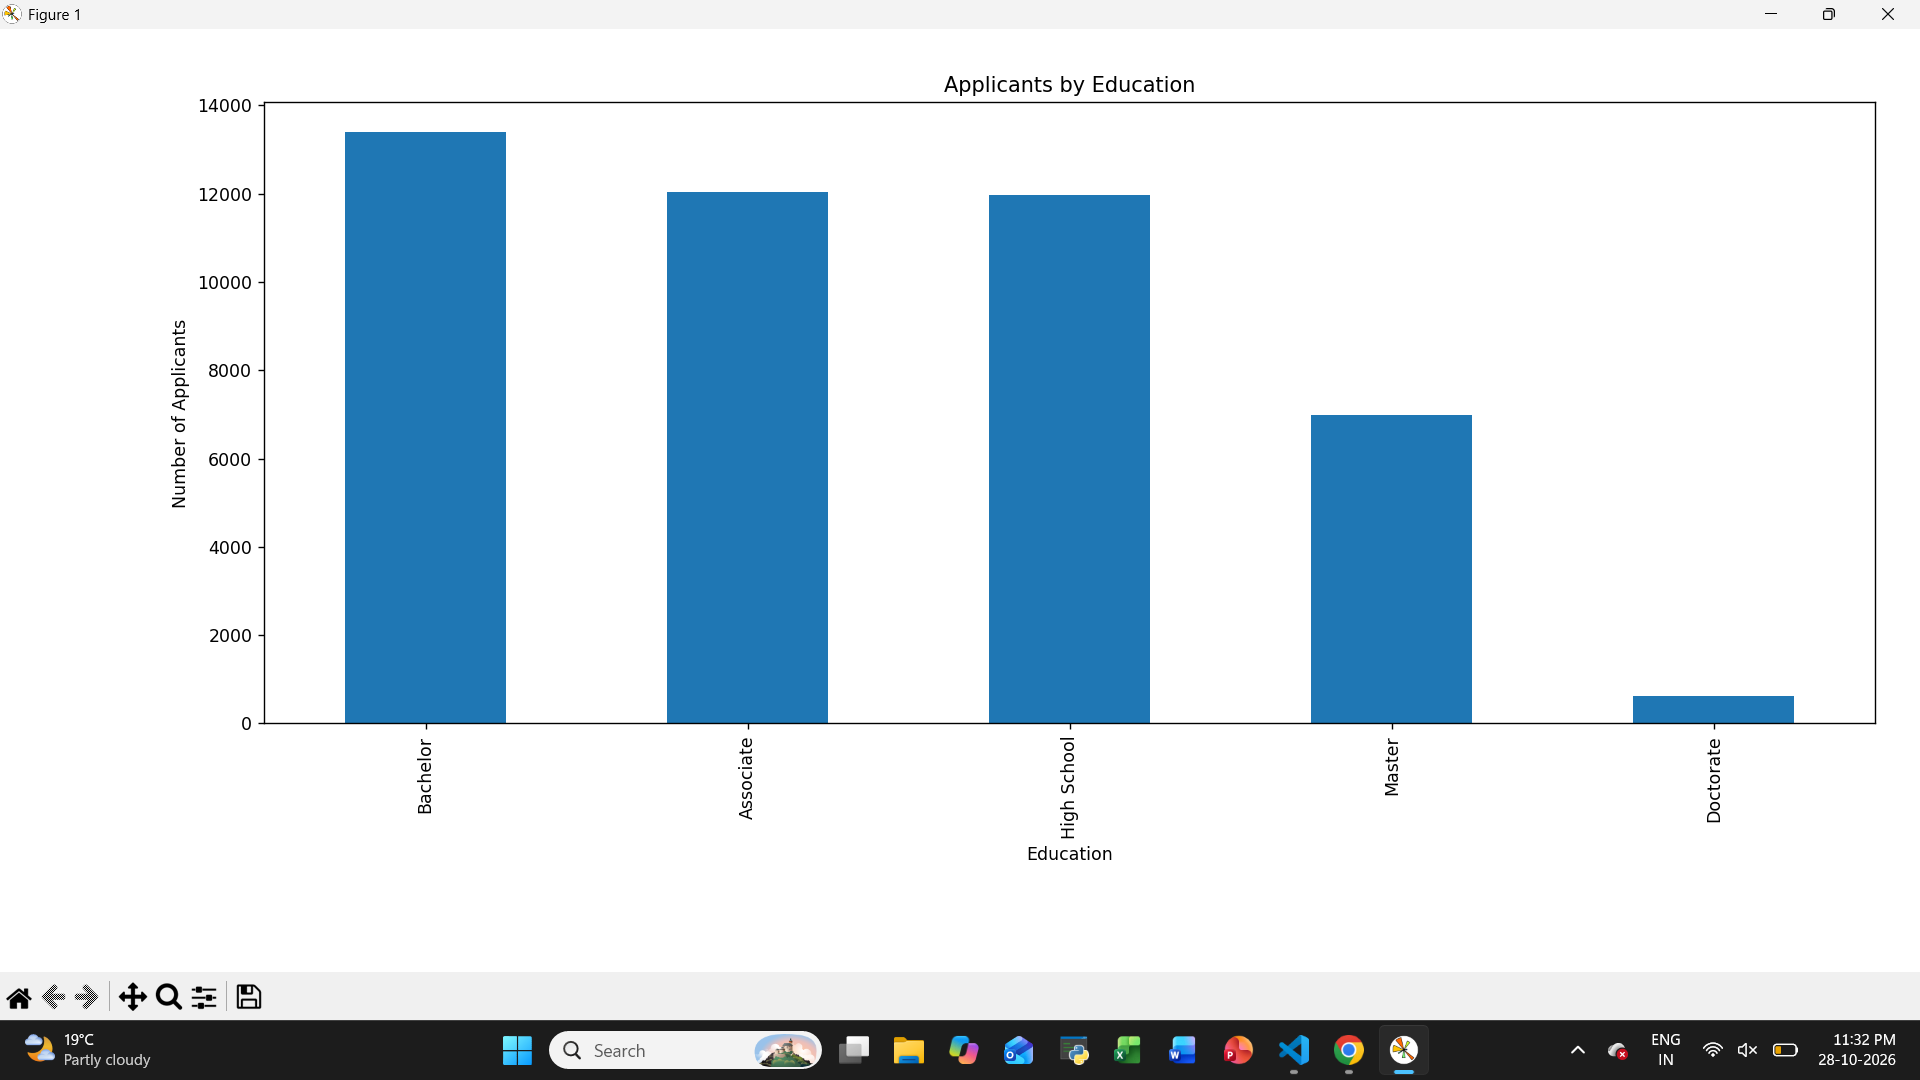

In [ ]:
# Embedded screenshot: Applicants by Education


### 3.4 Objective 3: Explore loan purposes

In [ ]:
print("Loan purposes:")
print(df["loan_intent"].value_counts())

df["loan_intent"].value_counts().plot(kind="bar")
plt.title("Loan Purpose Distribution")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Uploaded visualization: Loan Purpose Distribution**

This screenshot is included as a visual reference from the project run.


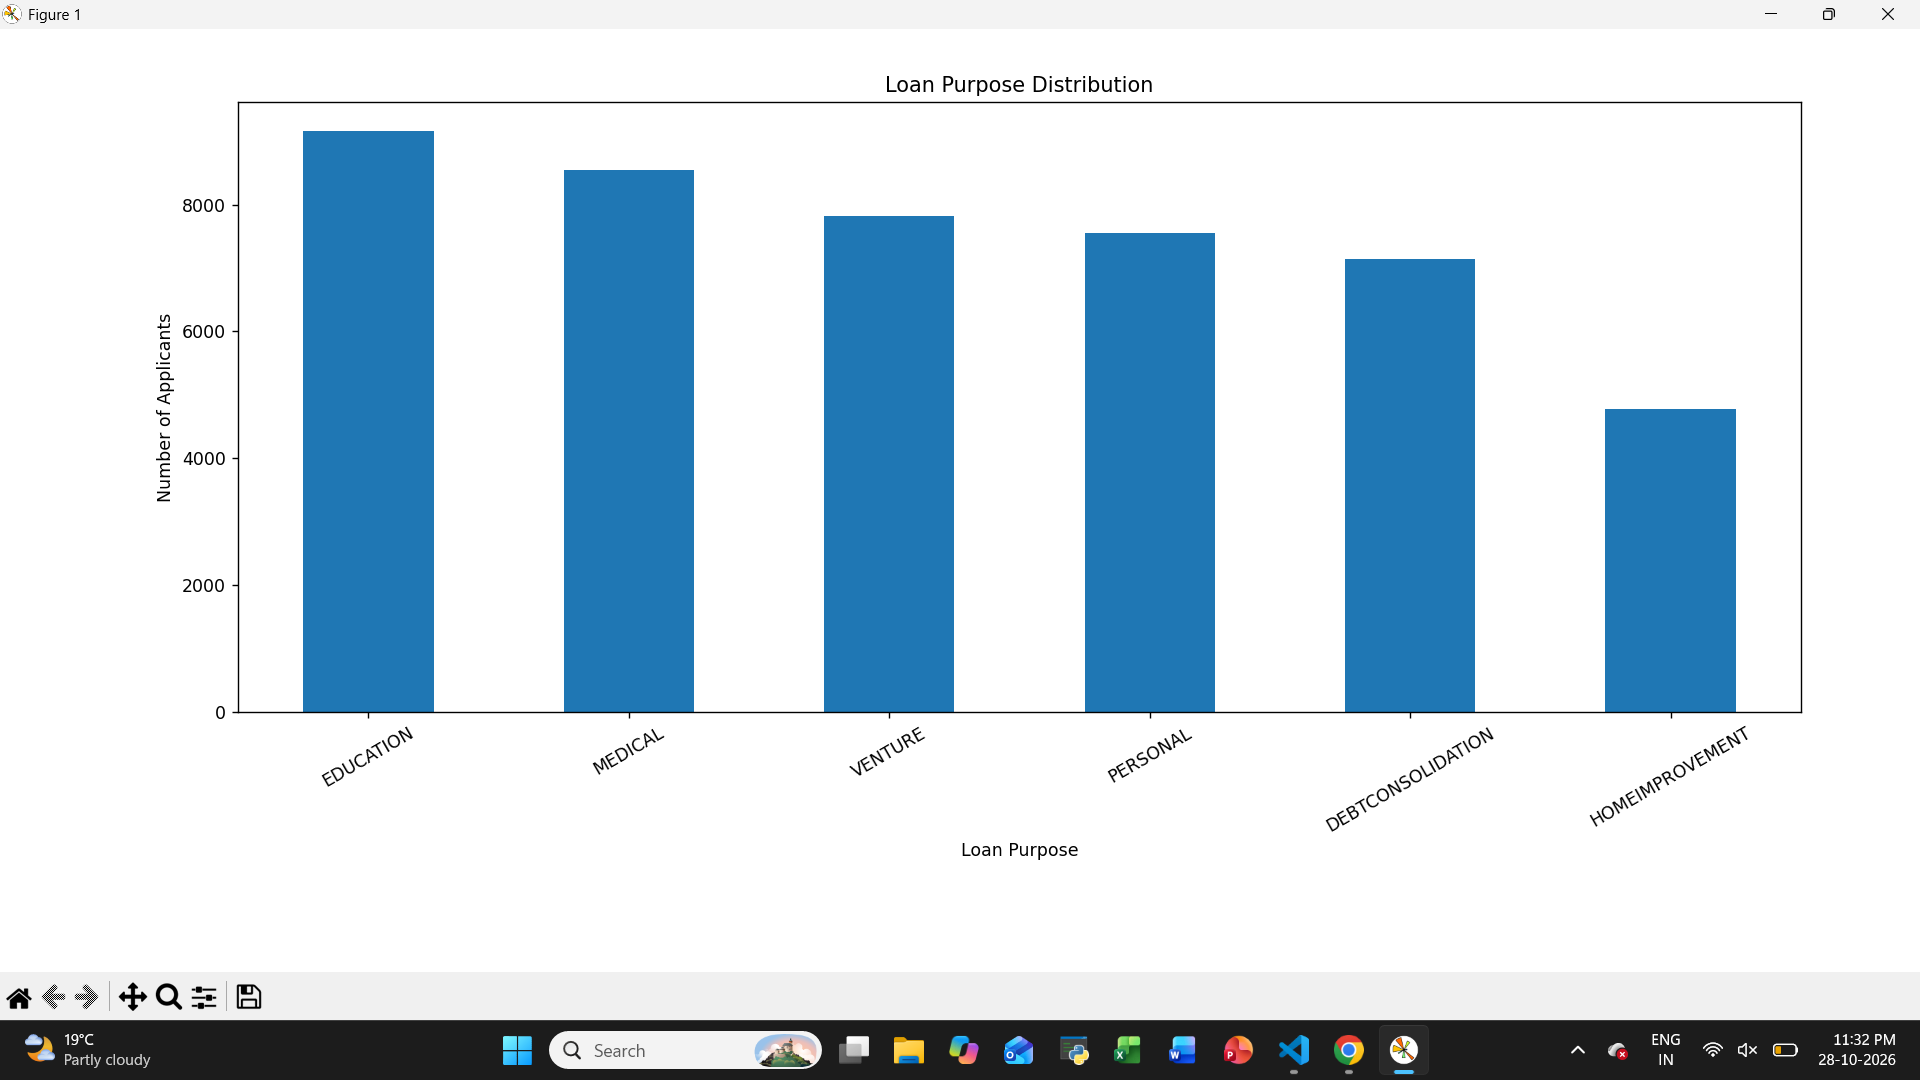

In [ ]:
# Embedded screenshot: Loan Purpose Distribution


### 3.5 Objective 4: Average loan amount by age

In [ ]:
avg_loan = df.groupby("person_age")["loan_amnt"].mean()

plt.figure(figsize=(9, 4))
plt.plot(avg_loan.index, avg_loan.values, marker="o")
plt.title("Average Loan Amount by Age")
plt.xlabel("Applicant Age")
plt.ylabel("Average Loan Amount")
plt.grid(True)
plt.tight_layout()
plt.show()

**Uploaded visualization: Average Loan Amount by Age**

This screenshot is included as a visual reference from the project run.


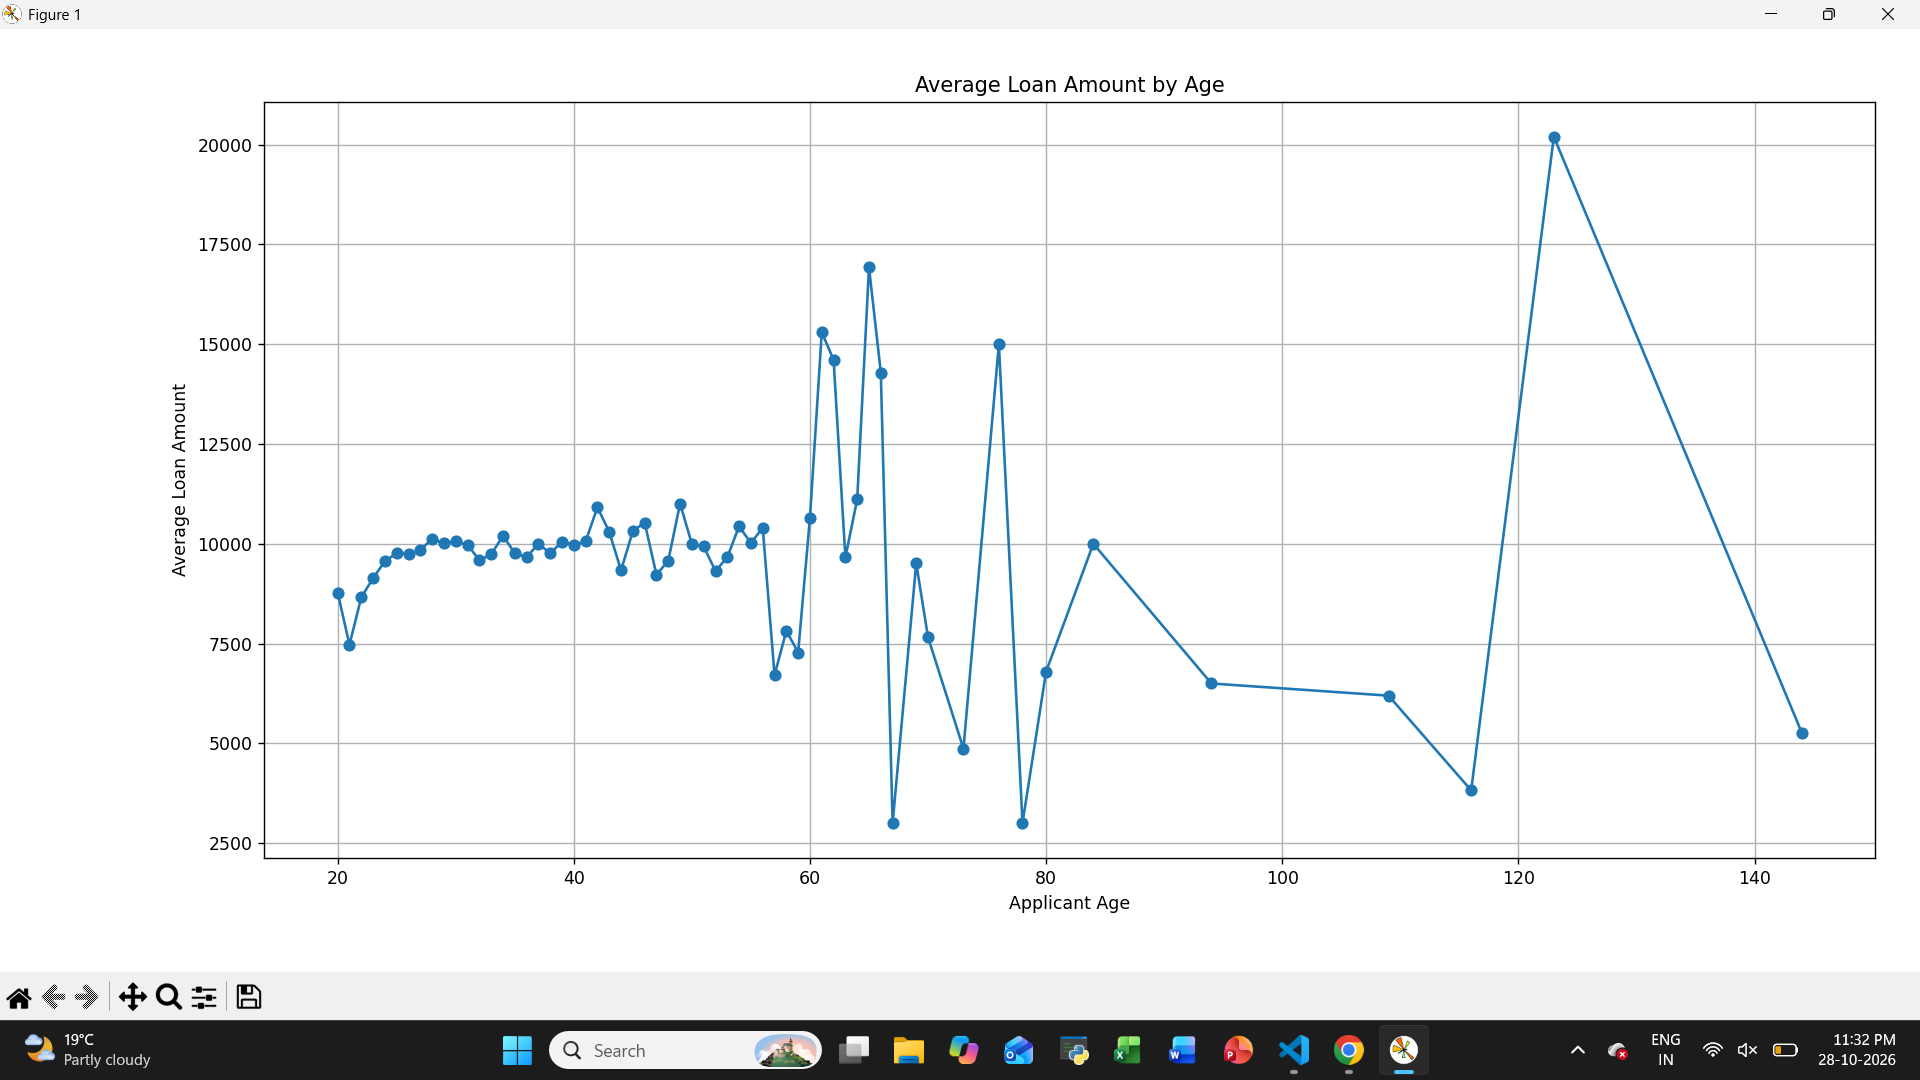

In [ ]:
# Embedded screenshot: Average Loan Amount by Age


### 3.6 Objective 5: Home ownership distribution

In [ ]:
df["person_home_ownership"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Applicants by Home Ownership")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Uploaded visualization: Applicants by Home Ownership**

This screenshot is included as a visual reference from the project run.


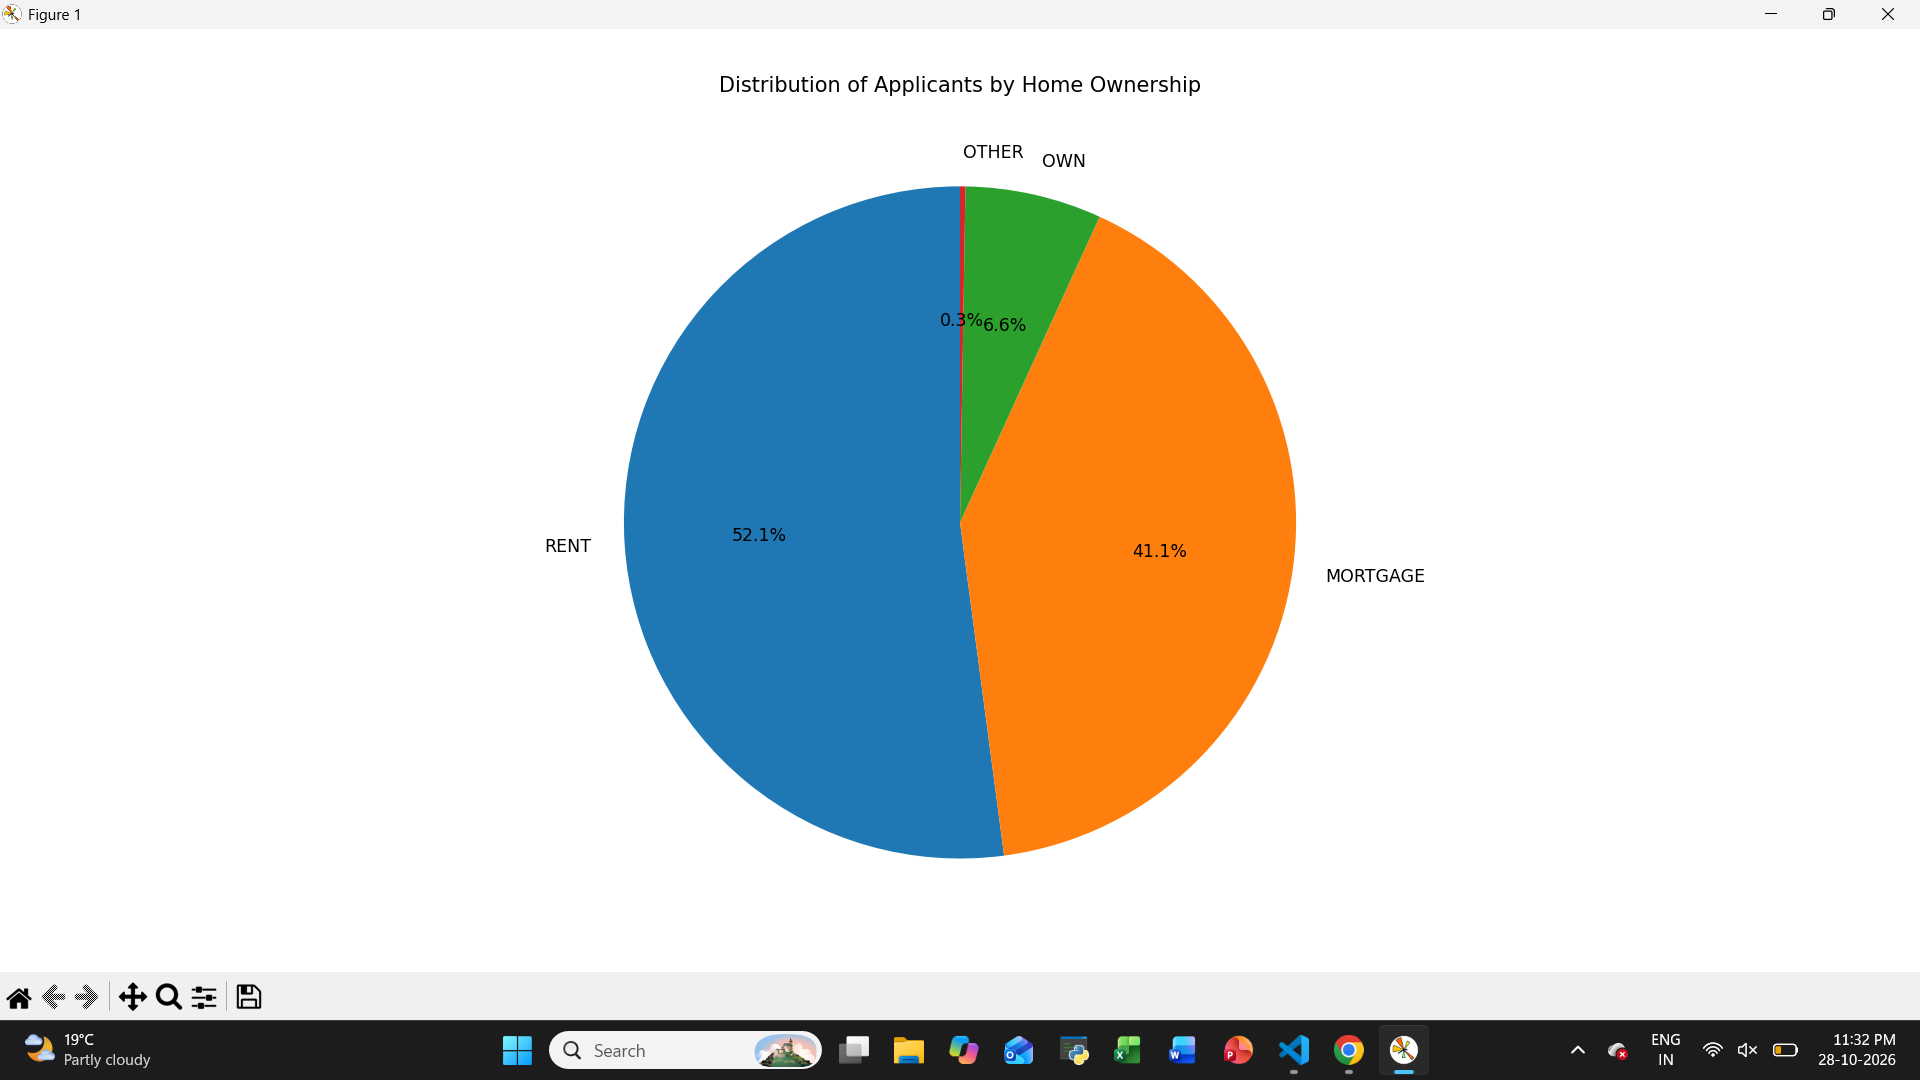

In [ ]:
# Embedded screenshot: Applicants by Home Ownership


### 3.7 Objective 6: Correlation heatmap

Correlation shows how numeric columns move in relation to one another. Correlation does not prove causation.

In [ ]:
numeric_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Uploaded visualization: Correlation Heatmap**

This screenshot is included as a visual reference from the project run.


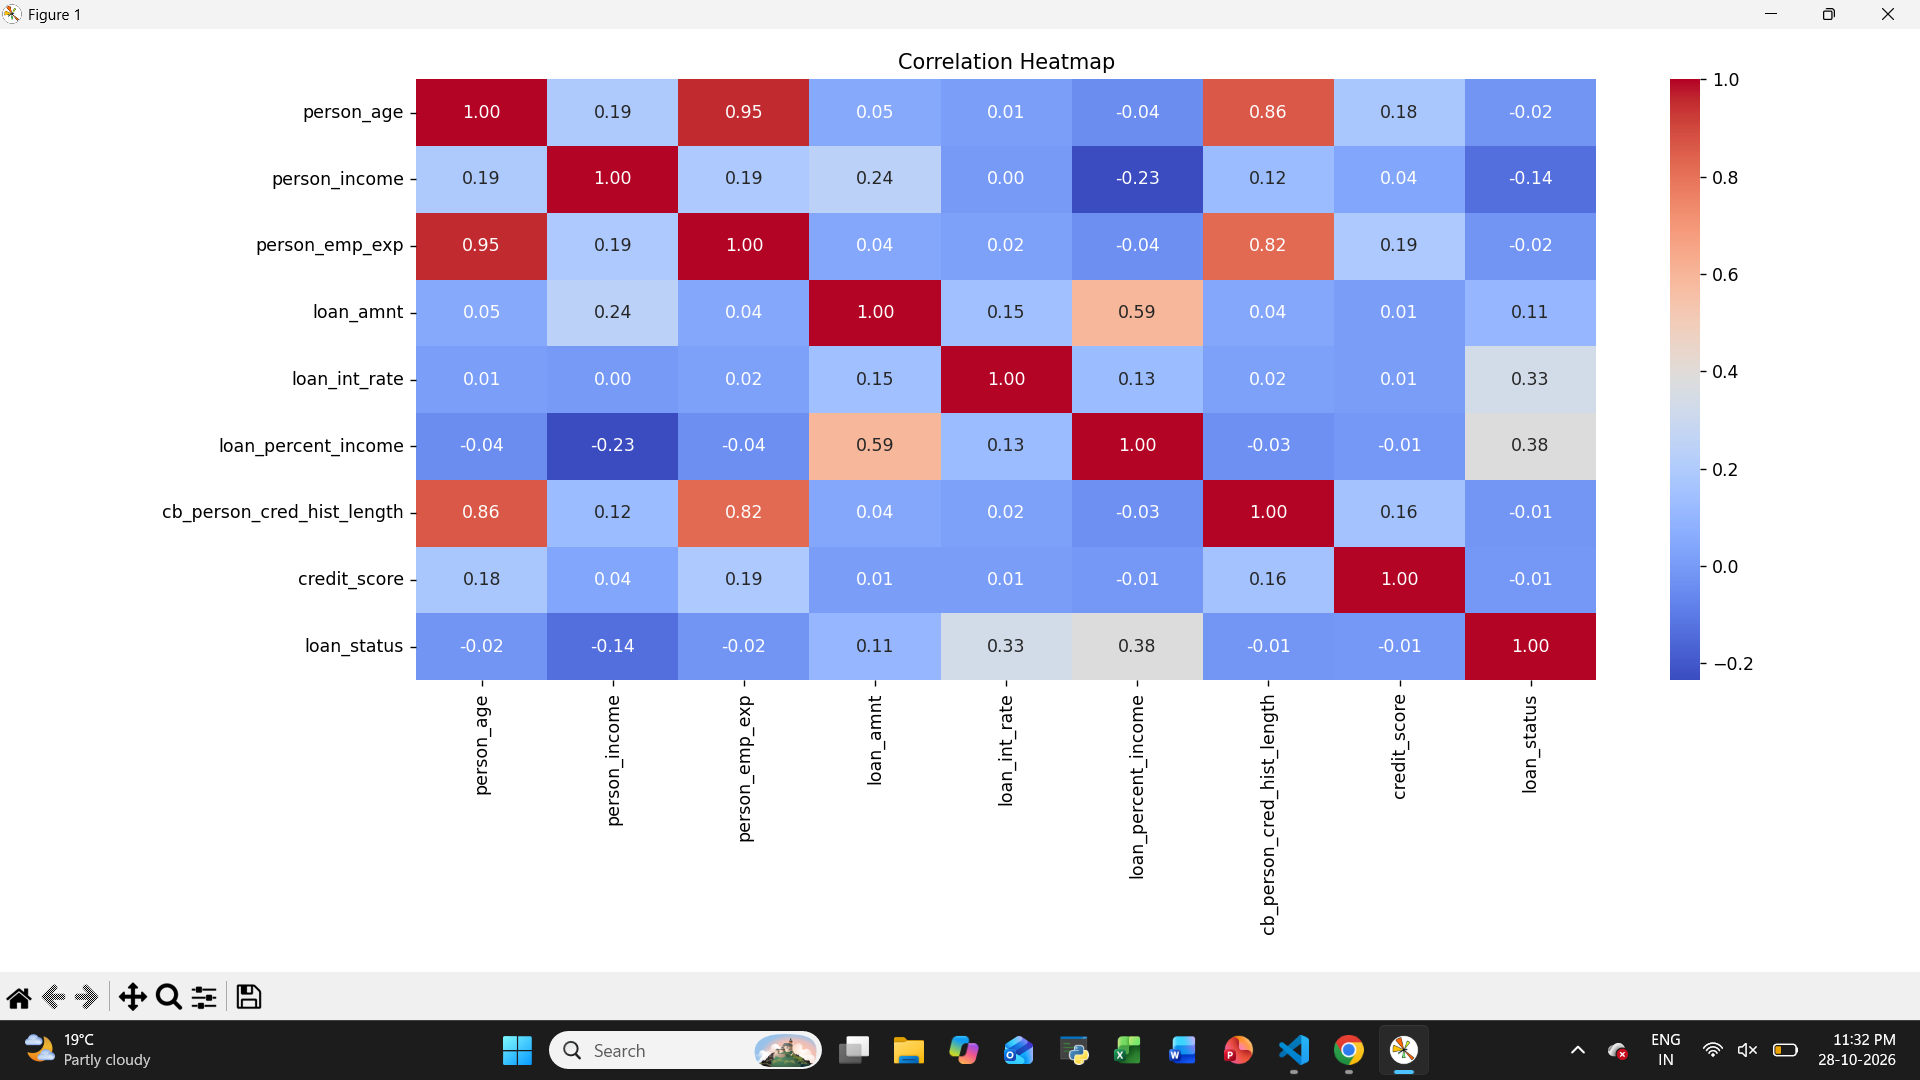

In [ ]:
# Embedded screenshot: Correlation Heatmap


## 4. Prepare data for Machine Learning

The target (`y`) is `loan_status`. The input features (`X`) contain all other columns.

This beginner-friendly version uses Label Encoding for text columns. Note that Label Encoding assigns numbers to categories; for some datasets, One-Hot Encoding may be a better choice.

In [ ]:
# Separate input features and target
X = df.drop("loan_status", axis=1).copy()
y = df["loan_status"].copy()

# Identify categorical columns
categorical_features = X.select_dtypes(include="object").columns

# Encode categorical columns
label_encoders = {}

for col in categorical_features:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col].astype(str))
    label_encoders[col] = encoder

print("Features after encoding:")
display(X.head())

print("\nTarget class counts:")
print(y.value_counts())

## 5. Split the dataset

We use 80% of the data for training and 20% for testing. `stratify=y` keeps the target-class proportions similar in both sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

## 6. Scale features for Logistic Regression and KNN

Scaling is useful for models that rely on distances or optimization. The scaler is fitted only on the training data to avoid leaking information from the test set.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Train and evaluate four classification models

For each model, this section prints accuracy, the confusion matrix, and the classification report.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print("\n" + "=" * 55)
    print("MODEL:", name)

    # Scale Logistic Regression and KNN inputs
    if name in ["KNN", "Logistic Regression"]:
        model.fit(X_train_scaled, y_train)
        prediction = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

    trained_models[name] = model

    accuracy = accuracy_score(y_test, prediction)
    results.append([name, accuracy])

    print("Accuracy:", round(accuracy * 100, 2), "%")

    cm = confusion_matrix(y_test, prediction, labels=[0, 1])
    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        prediction,
        labels=[0, 1],
        target_names=["Not Approved", "Approved"],
        zero_division=0
    ))

## 8. Visualize the Decision Tree

The plot is limited to depth 3 so it is easier to read. The trained model itself may be deeper.

In [ ]:
dt_model = trained_models["Decision Tree"]

plt.figure(figsize=(22, 12))
plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=["Not Approved", "Approved"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree - Loan Approval Prediction")
plt.tight_layout()
plt.show()

**Uploaded visualization: Decision Tree — Loan Approval Prediction**

This screenshot is included as a visual reference from the project run.


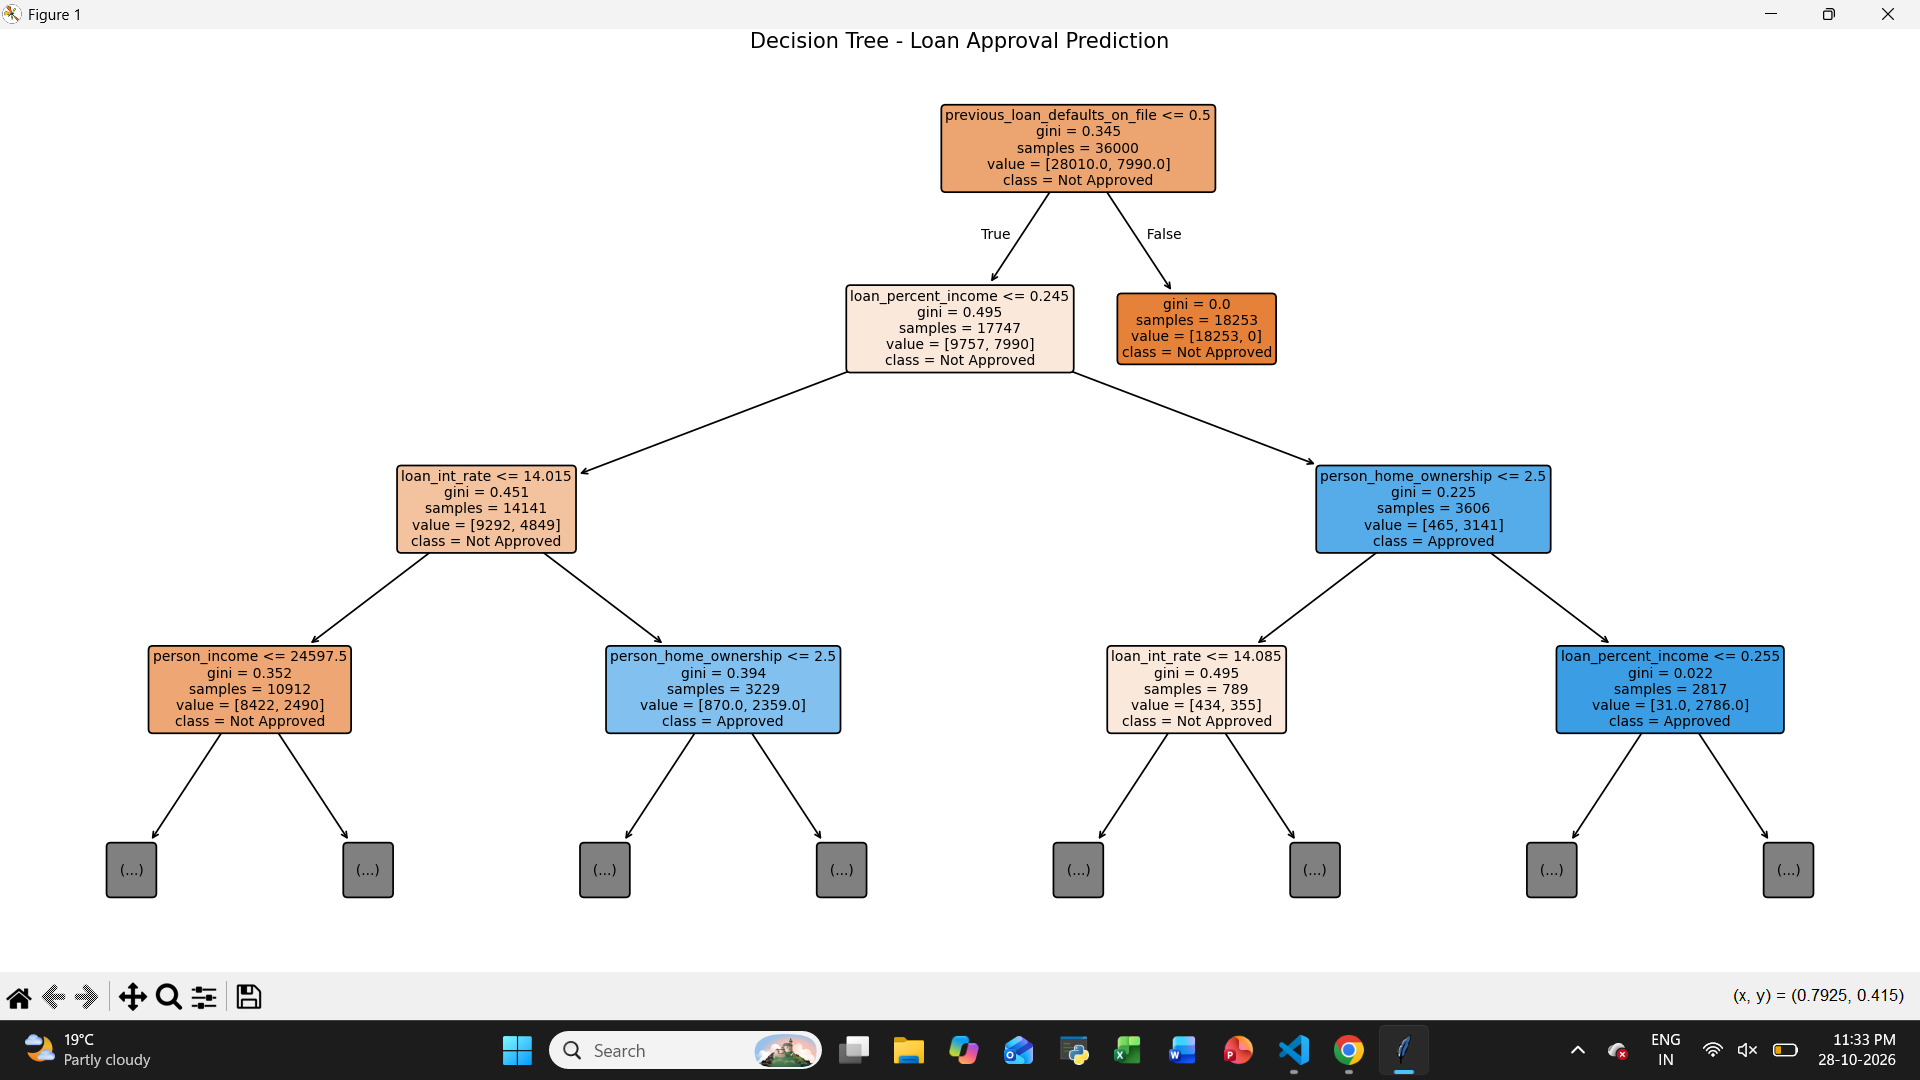

In [ ]:
# Embedded screenshot: Decision Tree — Loan Approval Prediction


## 9. Visualize one tree from the Random Forest

A Random Forest contains many decision trees. This cell displays the first tree, limited to depth 3 for readability.

In [ ]:
rf_model = trained_models["Random Forest"]

plt.figure(figsize=(22, 12))
plot_tree(
    rf_model.estimators_[0],
    feature_names=X_train.columns,
    class_names=["Not Approved", "Approved"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("First Decision Tree in Random Forest")
plt.tight_layout()
plt.show()

**Uploaded visualization: First Decision Tree in the Random Forest**

This screenshot is included as a visual reference from the project run.


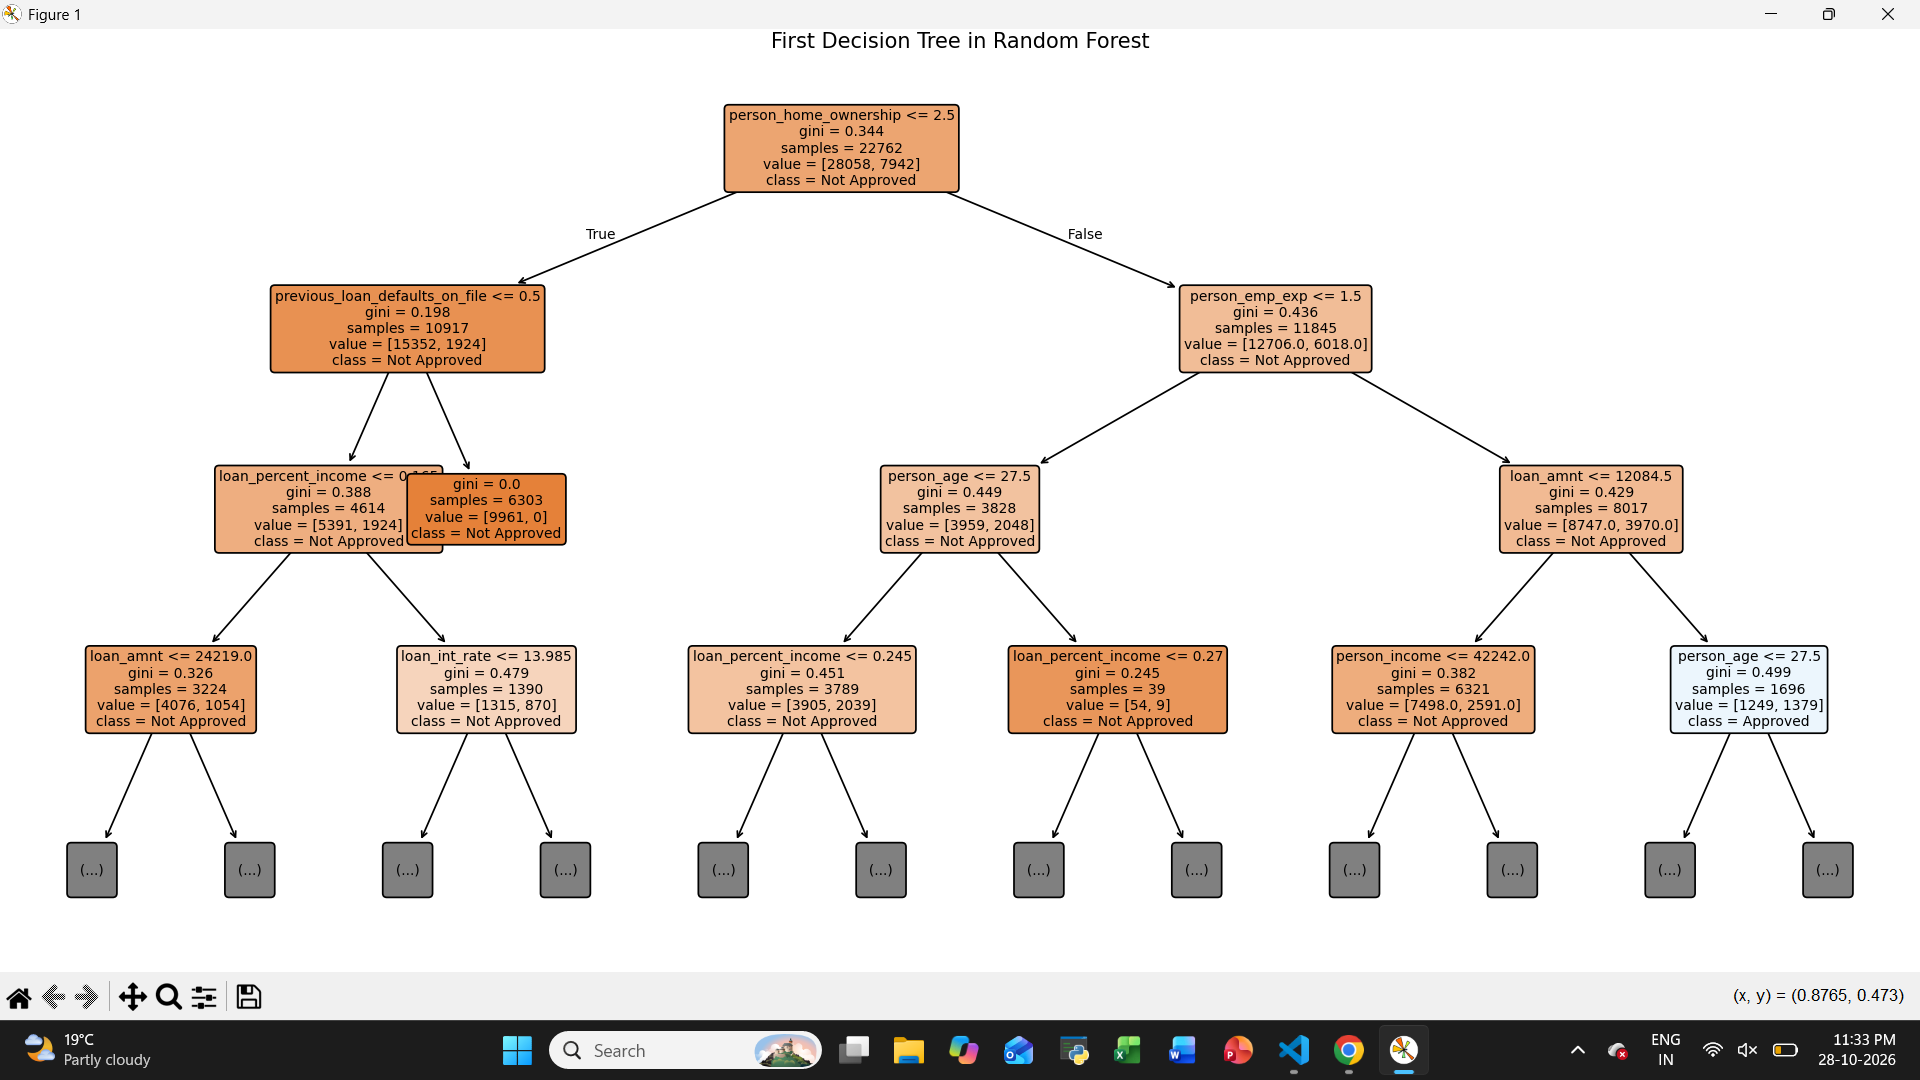

In [ ]:
# Embedded screenshot: First Decision Tree in the Random Forest


## 10. Compare model accuracy and identify the best model

The best model below is selected by test accuracy. For real loan decisions, accuracy alone is not enough; also consider precision, recall, fairness, and the cost of incorrect decisions.

In [ ]:
results_df = pd.DataFrame(results, columns=["Model", "Accuracy"])
results_df = results_df.sort_values("Accuracy", ascending=False).reset_index(drop=True)

print("Model Accuracy Comparison:")
display(results_df.assign(Accuracy=results_df["Accuracy"].map(lambda x: f"{x * 100:.2f}%")))

best_model_row = results_df.loc[results_df["Accuracy"].idxmax()]

print("\nBest Model:", best_model_row["Model"])
print("Best Accuracy:", round(best_model_row["Accuracy"] * 100, 2), "%")

results_df.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False,
    figsize=(9, 4)
)
plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Uploaded visualization: Classification Model Accuracy Comparison**

This screenshot is included as a visual reference from the project run.


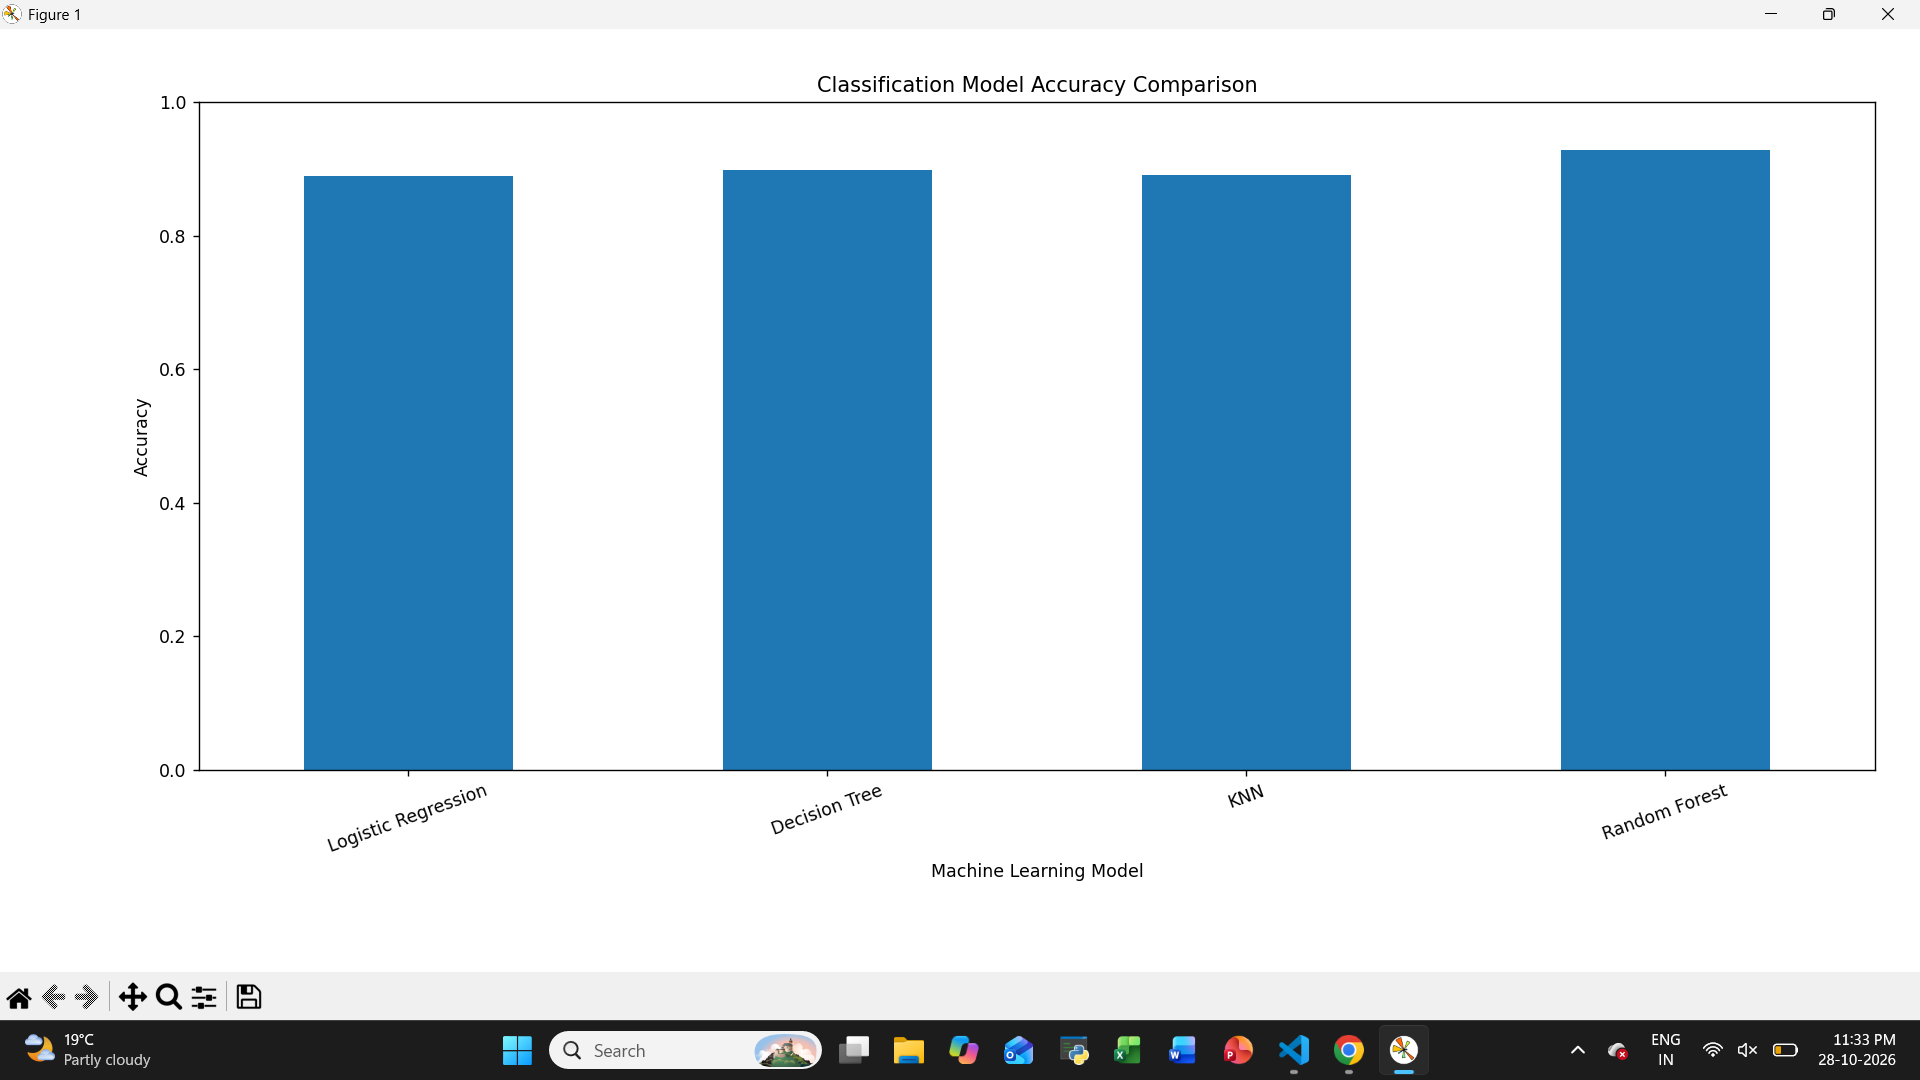

In [ ]:
# Embedded screenshot: Classification Model Accuracy Comparison


## 11. Conclusion

In the results previously obtained for this project, **Random Forest performed best with 92.87% accuracy**, followed by Decision Tree (89.81%), KNN (89.19%), and Logistic Regression (89.01%).

Your exact results may differ slightly if the dataset or preprocessing changes. The notebook calculates the best model from the current run.

**GitHub repository:** https://github.com/Prachimarria/Loan-Approval-Prediction